# Проверка гипотезы и графики

A/B тест новой формы оплаты ЖКХ (1-30 апреля 2024).

Гипотеза: новая форма с автозаполнением реквизитов (группа B) увеличит долю успешных оплат.

Данные: `ab_data.csv` - чистая таблица из `02_clean_data.sql`, выгруженная из PostgreSQL. Одна строка = одна попытка оплаты.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Загрузка данных

In [2]:
ab = pd.read_csv("ab_data.csv", parse_dates=["step1_opened", "step2_entered", "step3_confirmed", "step4_success"])
print(ab.shape)
ab.head()

(2658, 10)


,payment_id,user_id,group,age,city,device_type,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001,A,31,Москва,ios,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002,A,31,Москва,ios,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003,A,25,Москва,android,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004,A,20,Москва,ios,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004,A,20,Москва,ios,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


Сплит был по клиентам, поэтому делаю таблицу, где одна строка = один клиент.
`paid = 1`, если у клиента была хотя бы одна успешная оплата.

In [3]:
users = ab.groupby("user_id").agg(
    group=("group", "first"),
    device_type=("device_type", "first"),
    city=("city", "first"),
    age=("age", "first"),
    paid=("step4_success", lambda x: int(x.notna().any())),
).reset_index()

print(users.shape)
users.head()

(1501, 6)


,user_id,group,device_type,city,age,paid
0,1001,A,ios,Москва,31,0
1,1002,A,ios,Москва,31,0
2,1003,A,android,Москва,25,0
3,1004,A,ios,Москва,20,1
4,1005,A,ios,Москва,34,0


## Конверсия по группам

In [4]:
result = users.groupby("group")["paid"].agg(["count", "sum", "mean"])
result.columns = ["clients", "paid", "conversion"]
result["conversion"] = (result["conversion"] * 100).round(1)
result

,clients,paid,conversion
group,,,
A,751,492,65.5
B,750,603,80.4


## Статтест

Использую z-тест для двух долей:
- метрика бинарная (оплатил или нет), поэтому сравниваю две доли;
- клиенты независимы друг от друга;
- в каждой группе около 750 клиентов, этого достаточно для z-теста.

Уровень значимости 0.05.

In [5]:
n_a = result.loc["A", "clients"]
n_b = result.loc["B", "clients"]
k_a = result.loc["A", "paid"]
k_b = result.loc["B", "paid"]

p_a = k_a / n_a
p_b = k_b / n_b
diff = p_b - p_a

# z-тест
p_all = (k_a + k_b) / (n_a + n_b)
se = np.sqrt(p_all * (1 - p_all) * (1 / n_a + 1 / n_b))
z = diff / se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

# 95% доверительный интервал для разницы
se_diff = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
ci_low = diff - 1.96 * se_diff
ci_high = diff + 1.96 * se_diff

print(f"Конверсия A: {p_a:.1%}")
print(f"Конверсия B: {p_b:.1%}")
print(f"Разница: {diff * 100:.1f} п.п.")
print(f"95% доверительный интервал: от {ci_low * 100:.1f} до {ci_high * 100:.1f} п.п.")
print(f"z = {z:.2f}, p-value = {p_value:.1e}")

Конверсия A: 65.5%
Конверсия B: 80.4%
Разница: 14.9 п.п.
95% доверительный интервал: от 10.5 до 19.3 п.п.
z = 6.49, p-value = 8.5e-11


**Вывод:** конверсия выросла с 65.5% до 80.4%, на 14.9 п.п.
p-value намного меньше 0.05, доверительный интервал (примерно от 10.5 до 19.3 п.п.) не заходит в ноль.
Разница статистически значимая, гипотеза подтверждается.

## Воронка

In [6]:
steps = ["step1_opened", "step2_entered", "step3_confirmed", "step4_success"]
funnel = ab.groupby("group")[steps].count()
funnel_pct = (funnel.div(funnel["step1_opened"], axis=0) * 100).round(1)
funnel_pct

,step1_opened,step2_entered,step3_confirmed,step4_success
group,,,,
A,100.0,81.1,57.9,49.7
B,100.0,88.4,71.1,64.4


В группе B больше попыток доходит до каждого шага. Самая большая разница на шагах 2 и 3 - при вводе реквизитов, где и работает автозаполнение.

## Сегменты

In [7]:
by_device = users.pivot_table(index="device_type", columns="group", values="paid", aggfunc="mean") * 100
by_city = users.pivot_table(index="city", columns="group", values="paid", aggfunc="mean") * 100

segments = pd.concat([by_device, by_city])
segments = segments.rename(index={"ios": "iOS", "android": "Android"})
segments["diff"] = segments["B"] - segments["A"]
segments = segments.round(1)
segments

group,A,B,diff
Android,64.4,79.9,15.6
iOS,66.9,80.8,14.0
Москва,62.2,81.0,18.9
Регион,66.8,76.3,9.5
СПб,68.6,84.4,15.9


B лучше во всех сегментах. На iOS и Android рост почти одинаковый, поэтому небольшой перекос по Android в группе A на результат не влияет.
В регионах рост меньше (около 9.5 п.п.), но клиентов там немного, поэтому это скорее повод следить за регионами после запуска.

## Графики

In [8]:
os.makedirs("charts", exist_ok=True)

color_a = "tab:blue"
color_b = "tab:orange"

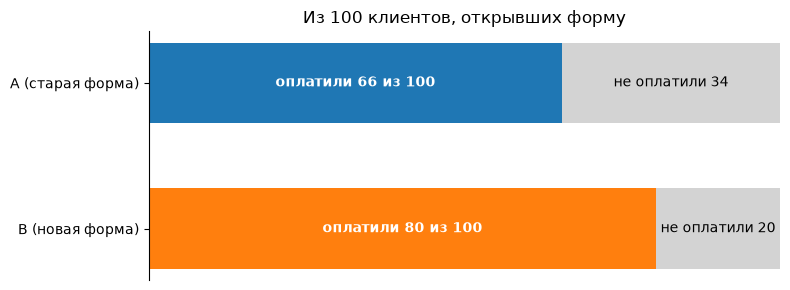

In [9]:
# График 1. Из 100 клиентов, открывших форму, сколько оплатили
paid = [result.loc["A", "conversion"], result.loc["B", "conversion"]]
names = ["A (старая форма)", "B (новая форма)"]

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(names, paid, color=[color_a, color_b], height=0.55)
ax.barh(names, [100 - p for p in paid], left=paid, color="lightgray", height=0.55)

for i, p in enumerate(paid):
    ax.text(p / 2, i, f"оплатили {p:.0f} из 100", ha="center", va="center", color="white", fontweight="bold")
    ax.text(p + (100 - p) / 2, i, f"не оплатили {100 - p:.0f}", ha="center", va="center")

ax.set_xlim(0, 100)
ax.set_xticks([])
ax.invert_yaxis()
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_title("Из 100 клиентов, открывших форму")

plt.tight_layout()
plt.savefig("charts/01_conversion.png", dpi=200)
plt.show()

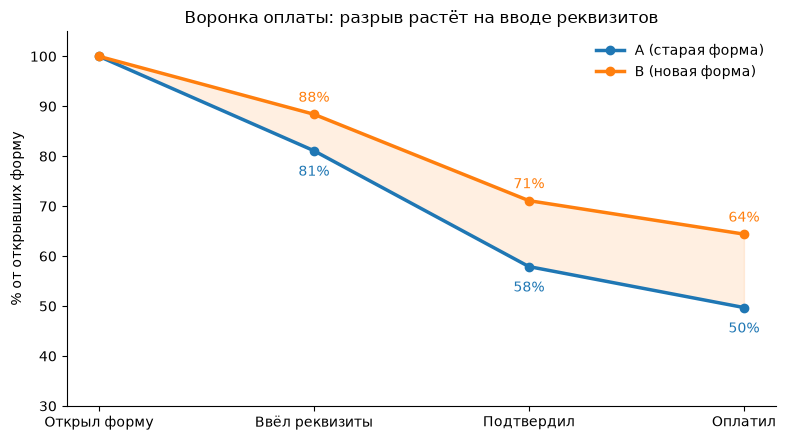

In [10]:
# График 2. Воронка линиями: где новая форма теряет меньше клиентов
labels = ["Открыл форму", "Ввёл реквизиты", "Подтвердил", "Оплатил"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(labels, funnel_pct.loc["A"], marker="o", linewidth=2.5, color=color_a, label="A (старая форма)")
ax.plot(labels, funnel_pct.loc["B"], marker="o", linewidth=2.5, color=color_b, label="B (новая форма)")
ax.fill_between(range(len(labels)), funnel_pct.loc["A"], funnel_pct.loc["B"], color=color_b, alpha=0.12)

for i in range(1, len(labels)):
    ax.text(i, funnel_pct.loc["B"].iloc[i] + 2.5, f"{funnel_pct.loc['B'].iloc[i]:.0f}%", ha="center", color=color_b)
    ax.text(i, funnel_pct.loc["A"].iloc[i] - 5, f"{funnel_pct.loc['A'].iloc[i]:.0f}%", ha="center", color=color_a)

ax.set_ylim(30, 105)
ax.set_ylabel("% от открывших форму")
ax.set_title("Воронка оплаты: разрыв растёт на вводе реквизитов")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/02_funnel.png", dpi=200)
plt.show()

Проверяю, что эффект не пропадает со временем (например, из-за эффекта новизны): считаю конверсию попыток по неделям теста.
29-30 апреля отношу к 4-й неделе.

In [11]:
ab["week"] = ((ab["step1_opened"].dt.day - 1) // 7 + 1).clip(upper=4)
weekly = ab.groupby(["week", "group"])["step4_success"].apply(lambda x: x.notna().mean() * 100).unstack().round(1)
weekly["diff"] = weekly["B"] - weekly["A"]
weekly

group,A,B,diff
week,,,
1,50.8,66.3,15.5
2,52.3,66.0,13.7
3,48.0,62.3,14.3
4,48.3,62.9,14.6


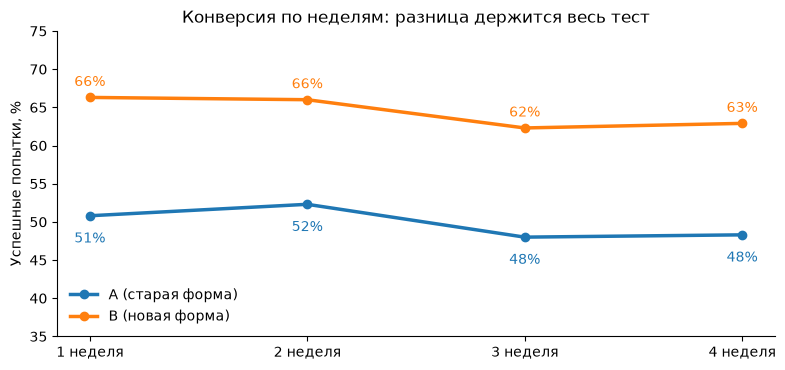

In [12]:
# График 6. Конверсия по неделям теста
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(weekly.index, weekly["A"], marker="o", linewidth=2.5, color=color_a, label="A (старая форма)")
ax.plot(weekly.index, weekly["B"], marker="o", linewidth=2.5, color=color_b, label="B (новая форма)")

for week in weekly.index:
    ax.text(week, weekly.loc[week, "B"] + 1.5, f"{weekly.loc[week, 'B']:.0f}%", ha="center", color=color_b)
    ax.text(week, weekly.loc[week, "A"] - 3.5, f"{weekly.loc[week, 'A']:.0f}%", ha="center", color=color_a)

ax.set_xticks(weekly.index, ["1 неделя", "2 неделя", "3 неделя", "4 неделя"])
ax.set_ylim(35, 75)
ax.set_ylabel("Успешные попытки, %")
ax.set_title("Конверсия по неделям: разница держится весь тест")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/06_weekly.png", dpi=200)
plt.show()

Разница между группами каждую неделю около 14-15 п.п. и не уменьшается к концу теста, то есть эффект стабильный, а не только из-за новизны.

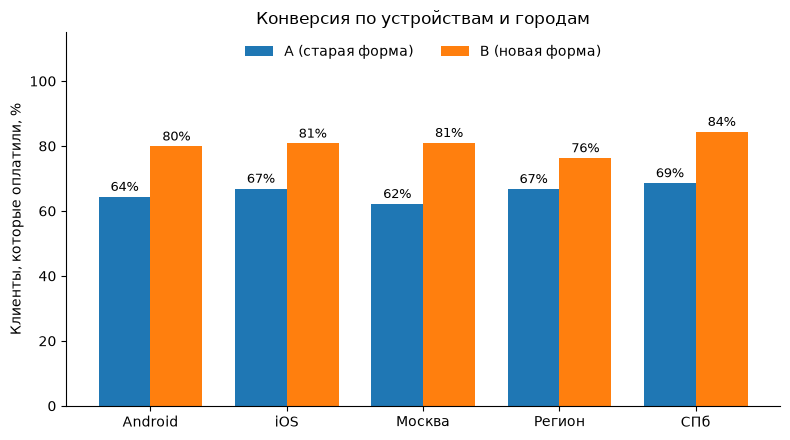

In [13]:
# График 3. Конверсия по устройствам и городам
labels = segments.index
x = np.arange(len(labels))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
bars_a = ax.bar(x - width / 2, segments["A"], width, label="A (старая форма)", color=color_a)
bars_b = ax.bar(x + width / 2, segments["B"], width, label="B (новая форма)", color=color_b)
ax.bar_label(bars_a, fmt="%.0f%%", padding=2, fontsize=9)
ax.bar_label(bars_b, fmt="%.0f%%", padding=2, fontsize=9)

ax.set_xticks(x, labels)
ax.set_ylim(0, 115)
ax.set_ylabel("Клиенты, которые оплатили, %")
ax.set_title("Конверсия по устройствам и городам")
ax.legend(loc="upper center", ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/03_segments.png", dpi=200)
plt.show()

### Данные, на которых делался анализ

Ящик с усами показывает распределение: линия внутри ящика - медиана, ящик - средние 50% значений,
усы - обычный разброс, отдельные точки - выбросы.

Возраст до очистки берём из исходного файла `raw_data.xlsx`, после очистки - из `ab_data.csv`.

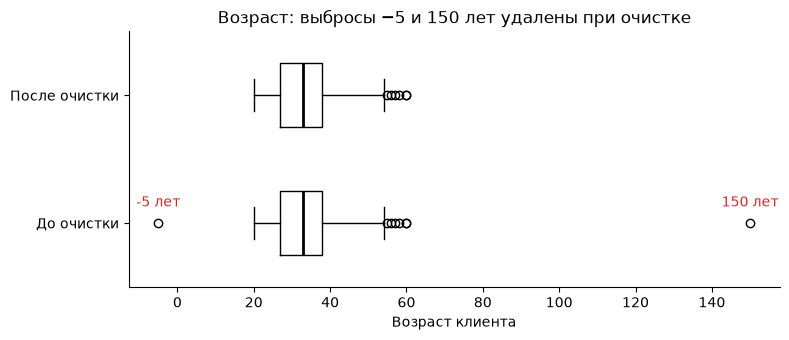

In [14]:
# График 4. Возраст до и после очистки
raw_users = pd.read_excel("raw_data.xlsx", sheet_name="Пользователи")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([raw_users["age"], users["age"]], orientation="horizontal", widths=0.5,
           tick_labels=["До очистки", "После очистки"], medianprops={"color": "black", "linewidth": 2})

for value in [raw_users["age"].min(), raw_users["age"].max()]:
    ax.annotate(f"{value} лет", (value, 1), textcoords="offset points", xytext=(0, 12), ha="center", color="tab:red")

ax.set_xlabel("Возраст клиента")
ax.set_title("Возраст: выбросы −5 и 150 лет удалены при очистке")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/04_age_boxplot.png", dpi=200)
plt.show()

Точки справа от ящика после очистки (55-60 лет) - это не ошибки. Ящик с усами отмечает их как выбросы по формальному правилу,
но такой возраст нормальный для клиента банка, поэтому эти записи я оставил. Удалены только -5 и 150 лет.

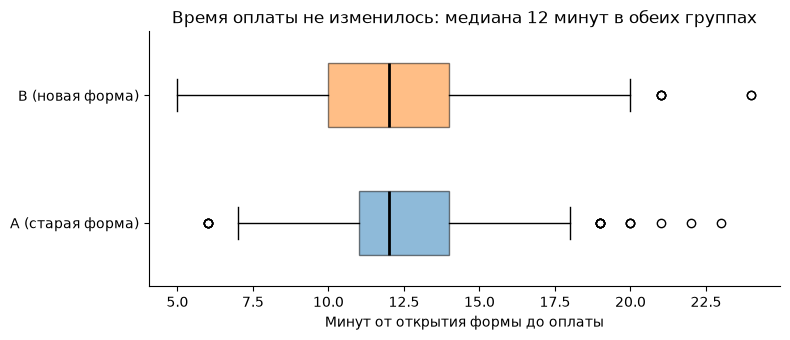

In [15]:
# График 5. Время успешной оплаты по группам
success = ab[ab["step4_success"].notna()].copy()
success["minutes"] = (success["step4_success"] - success["step1_opened"]).dt.total_seconds() / 60

fig, ax = plt.subplots(figsize=(8, 3.5))
box = ax.boxplot([success.loc[success["group"] == "A", "minutes"], success.loc[success["group"] == "B", "minutes"]],
                 orientation="horizontal", widths=0.5, patch_artist=True, tick_labels=["A (старая форма)", "B (новая форма)"],
                 medianprops={"color": "black", "linewidth": 2})
for patch, color in zip(box["boxes"], [color_a, color_b]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax.set_xlabel("Минут от открытия формы до оплаты")
ax.set_title("Время оплаты не изменилось: медиана 12 минут в обеих группах")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("charts/05_time_boxplot.png", dpi=200)
plt.show()

## Итог

- Конверсия на клиента: A 65.5%, B 80.4%, разница +14.9 п.п. Разница статистически значимая (p-value < 0.05).
- В B больше людей проходят каждый шаг воронки, особенно ввод реквизитов.
- Рост есть на iOS, Android и во всех городах, в регионах меньше.
- Время оплаты не изменилось (медиана 12 минут в обеих группах).
- Эффект стабильный: каждую неделю теста разница около 14-15 п.п.
- На каждую 1000 клиентов, открывших форму, примерно на 149 больше успешно оплативших.

**Рекомендация:** запускать новую форму на всех пользователей. После запуска следить за конверсией в регионах.